In [1]:
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from scipy.spatial.distance import jensenshannon
from scipy.stats import entropy
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from multifidelity_end2end import create_low_fidelity, separate_hf_and_lf_train
import argparse

/home/kpg/miniconda3/envs/chemprop/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# def calculate_similarity_metrics(fps1, fps2):
#     # Calculate Tanimoto similarities
#     # tanimoto_sims = [DataStructs.FingerprintSimilarity(fp1, fp2) for fp1 in fps1 for fp2 in fps2]

#     # Calculate Cosine similarities
#     # cosine_sims = [DataStructs.BulkTanimotoSimilarity(fp1, fp2, returnDistance=False) for fp1 in fps1 for fp2 in fps2]

#     # Calculate Dice similarities
#     # dice_sims = [DataStructs.BulkDiceSimilarity(fp1, fp2) for fp1 in fps1 for fp2 in fps2]

#     # Calculate KL Divergence - approximate for binary vectors by treating them as probability distributions
#     def kl_divergence(fp1, fp2):
#         p = np.array(fp1)
#         q = np.array(fp2) + 1e-10  # avoid division by zero
#         return entropy(p, q)
    
#     kl_divs = [kl_divergence(fp1, fp2) for fp1 in fps1 for fp2 in fps2]

#     # Calculate Jensen-Shannon Divergence
#     def js_divergence(fp1, fp2):
#         p = np.array(fp1)
#         q = np.array(fp2)
#         m = 0.5 * (p + q)
#         return 0.5 * (entropy(p, m) + entropy(q, m))

#     js_divs = [js_divergence(fp1, fp2) for fp1 in fps1 for fp2 in fps2]

#     # Summary statistics for Tanimoto, Cosine, and Dice similarities
#     metrics = {
#         # 'Tanimoto': {
#         #     'Min': np.min(tanimoto_sims),
#         #     'Max': np.max(tanimoto_sims),
#         #     'Mean': np.mean(tanimoto_sims),
#         #     'Median': np.median(tanimoto_sims),
#         #     'Std': np.std(tanimoto_sims)
#         # },
#         # 'Cosine': {
#         #     'Min': np.min(cosine_sims),
#         #     'Max': np.max(cosine_sims),
#         #     'Mean': np.mean(cosine_sims),
#         #     'Median': np.median(cosine_sims),
#         #     'Std': np.std(cosine_sims)
#         # },
#         # 'Dice': {
#         #     'Min': np.min(dice_sims),
#         #     'Max': np.max(dice_sims),
#         #     'Mean': np.mean(dice_sims),
#         #     'Median': np.median(dice_sims),
#         #     'Std': np.std(dice_sims)
#         # },
#         'KL Divergence - mean': np.mean(kl_divs),
#         'KL Divergence - median': np.median(kl_divs),
#         'KL Divergence - sum': np.sum(kl_divs),
#         'JS Divergence - mean': np.mean(js_divs),
#         'JS Divergence - median': np.median(js_divs),
#         'JS Divergence - sum': np.sum(js_divs)
#     }

#     return metrics

# # Example usage - assuming fingerprints are already computed
# # fps1 = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(smile), 2) for smile in smiles_set_1]
# # fps2 = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(smile), 2) for smile in smiles_set_2]

# # metrics = calculate_similarity_metrics(fps1, fps2)
# # print(metrics)


In [3]:
# ratios_and_supersets = [
#     # [1, True],
#     # [10, True],
#     [100, True],
#     # [1, False],
#     # [10, False],
#     [100, False],
#     ]

# # create a dataframe to store the results
# # column_list = ['add_pn_bias_to_make_lf', 'add_constant_bias_to_make_lf', 'add_gauss_noise_to_make_lf', 
# #                 'add_descriptor_bias_to_make_lf', 'mape', 'wmape', 'mae', 'rmse', 'r_squared', 'median_ae', 
# #                 'explained_variance', 'max_err', 'spearman_corr', 'pearson_corr', 'kendall_corr', 'covariance', 
# #                 'corrcoef', 'rogi_hf', 'rogi_lf', 'rogi_diff', 'rogi_absdiff', 'rogi_hf_desc_euc', 'rogi_lf_desc_euc', 
# #                 'rogi_diff_desc_euc', 'rogi_absdiff_desc_euc', 'rogi_hf_desc_cos', 'rogi_lf_desc_cos', 'rogi_diff_desc_cos', 'rogi_absdiff_desc_cos']
# # results_df = pd.DataFrame(columns=column_list)
                       
# for ratio_and_superset in ratios_and_supersets:
#     df = pd.read_csv('tests/data/gdb11_0.0001.csv')
#     df.rename(columns={'h298': 'h298_HF'}, inplace=True)

#     args = argparse.Namespace()

#     args.lf_col_name = 'h298_LF'
#     args.hf_col_name = 'h298_HF'
#     args.add_pn_bias_to_make_lf = 0
#     args.add_constant_bias_to_make_lf = 0
#     args.add_gauss_noise_to_make_lf = 0
#     args.add_descriptor_bias_to_make_lf = 0
#     args.lf_hf_size_ratio = ratio_and_superset[0]
#     args.lf_superset_of_hf = ratio_and_superset[1]
#     args.seed = 0

#     df.set_index('smiles', inplace=True)
#     df = create_low_fidelity(df, args)
#     df, _, _ = separate_hf_and_lf_train(df, list(df.index), args)
#     df.reset_index(inplace=True)
    
#     print(f"Ratio and superset: {ratio_and_superset}")
    
#     print("Similarity metrics")
    
#     # Calculate Morgan fingerprints for all compounds
#     fps = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(smile), 2) for smile in df['smiles']]

#     # compare fps with SD values to those with DR values not NaN
#     fps_lf = [fps[i] for i in range(len(df)) if not np.isnan(df['h298_LF'][i])]
#     fps_hf = [fps[i] for i in range(len(df)) if not np.isnan(df['h298_HF'][i])]

#     metrics = calculate_similarity_metrics(fps_lf, fps_hf)
#     print(metrics)
#     print()

#     # store all the results in a dataframe
#     # results_df = pd.concat([results_df, pd.DataFrame([[noise_and_bias[0], noise_and_bias[1], noise_and_bias[2], noise_and_bias[3],
#     #                                          mape, wmape, mae, rmse, r_squared, median_ae, explained_variance, 
#     #                                          max_err, spearman_corr, pearson_corr, kendall_corr, covariance, corrcoef,
#     #                                          rogi_hf, rogi_lf, rogi_diff, rogi_absdiff, rogi_hf_desc_euc, rogi_lf_desc_euc, 
#     #                                          rogi_diff_desc_euc, rogi_absdiff_desc_euc, rogi_hf_desc_cos, rogi_lf_desc_cos, 
#     #                                          rogi_diff_desc_cos, rogi_absdiff_desc_cos]], columns=column_list)])   

# # results_df

In [4]:
def smiles_to_fingerprints(smiles_list, radius=2, nBits=1024):
    """
    Convert a list of SMILES strings to Morgan fingerprints.
    
    Parameters:
    - smiles_list: List of SMILES strings representing molecules.
    - radius: Radius parameter for Morgan fingerprint.
    - nBits: Number of bits in the generated fingerprint.
    
    Returns:
    - A numpy array where each row is the binary vector (fingerprint) of a molecule.
    """
    fingerprints = []
    for smiles in smiles_list:
        mol = Chem.MolFromSmiles(smiles)
        if mol is not None:  # Check if the molecule is valid
            fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits)
            arr = np.zeros((0,), dtype=int)
            DataStructs.ConvertToNumpyArray(fp, arr)
            fingerprints.append(arr)
    return np.array(fingerprints)

def compute_kl_divergence(set1, set2):
    """
    Compute the KL divergence between two sets of binary vectors.
    
    Parameters:
    - set1: A numpy array of binary vectors.
    - set2: A numpy array of binary vectors.
    
    Returns:
    - The KL divergence from set1 to set2.
    """
    # Estimate probabilities for each bit being 1 in set1 and set2
    p_i = np.mean(set1, axis=0)
    q_i = np.mean(set2, axis=0)
    
    # Ensure p_i and q_i are not 0 or 1 to avoid division by zero or log(0) in calculations
    p_i = np.clip(p_i, 1e-10, 1 - 1e-10)
    q_i = np.clip(q_i, 1e-10, 1 - 1e-10)
    
    # Compute KL divergence for each bit and sum
    kl_divergence = np.sum(p_i * np.log(p_i / q_i) + (1 - p_i) * np.log((1 - p_i) / (1 - q_i)))
    
    return kl_divergence

def compute_js_divergence(set1, set2):
    """
    Compute the JS divergence between two sets of binary vectors.
    
    Parameters:
    - set1: A numpy array of binary vectors.
    - set2: A numpy array of binary vectors.
    
    Returns:
    - The JS divergence between set1 and set2.
    """
    # Estimate probabilities for each bit being 1 in set1 and set2
    p = np.mean(set1, axis=0)
    q = np.mean(set2, axis=0)
    
    # Ensure probabilities are within valid range to avoid log(0)
    p = np.clip(p, 1e-10, 1 - 1e-10)
    q = np.clip(q, 1e-10, 1 - 1e-10)
    
    # Compute the midpoint distribution
    m = 0.5 * (p + q)
    
    # Compute KL divergences to the midpoint
    kl_pm = compute_kl_divergence(p, m)
    kl_qm = compute_kl_divergence(q, m)
    
    # Compute JS divergence
    js_divergence = 0.5 * (kl_pm + kl_qm)
    
    return js_divergence

# Synthetic Dataset

In [5]:
ratios_and_supersets = [
    [1, True],
    [10, True],
    [100, True],
    [1, False],
    [10, False],
    [100, False],
    ]

kl_divergences = {ratios_and_supersets[i][0]: {ratios_and_supersets[i][1]: None} for i in range(len(ratios_and_supersets))}
kl_divergences_flipped = {ratios_and_supersets[i][0]: {ratios_and_supersets[i][1]: None} for i in range(len(ratios_and_supersets))}
js_divergences = {ratios_and_supersets[i][0]: {ratios_and_supersets[i][1]: None} for i in range(len(ratios_and_supersets))}
                       
for ratio_and_superset in ratios_and_supersets:
    df = pd.read_csv('tests/data/gdb11_0.001.csv')
    df.rename(columns={'h298': 'h298_HF'}, inplace=True)

    args = argparse.Namespace()

    args.lf_col_name = 'h298_LF'
    args.hf_col_name = 'h298_HF'
    args.add_pn_bias_to_make_lf = 0
    args.add_constant_bias_to_make_lf = 0
    args.add_gauss_noise_to_make_lf = 0
    args.add_descriptor_bias_to_make_lf = 0
    args.lf_hf_size_ratio = ratio_and_superset[0]
    args.lf_superset_of_hf = ratio_and_superset[1]
    args.seed = 0

    df.set_index('smiles', inplace=True)
    df = create_low_fidelity(df, args)
    df, _, _ = separate_hf_and_lf_train(df, list(df.index), args)
    df.reset_index(inplace=True)
    
    print(f"Ratio and superset: {ratio_and_superset}")
    
    print("Similarity metrics")

    # Extract SMILES strings for each set
    smis_lf = [df['smiles'][i] for i in range(len(df)) if not np.isnan(df['h298_LF'][i])]
    smis_hf = [df['smiles'][i] for i in range(len(df)) if not np.isnan(df['h298_HF'][i])]
    
    # Convert SMILES to Morgan fingerprints
    fp_set_lf = smiles_to_fingerprints(smis_lf)
    fp_set_hf = smiles_to_fingerprints(smis_hf)

    # Compute KL divergence
    kl_divergence = compute_kl_divergence(fp_set_hf, fp_set_lf)  # this is the correct order - "surprise from using LF as model when HF is the real model"
    kl_divergence_flipped = compute_kl_divergence(fp_set_lf, fp_set_hf)
    js_divergence = compute_js_divergence(fp_set_hf, fp_set_lf)
    print("KL Divergence:", kl_divergence)
    print("KL Divergence - flipped:", kl_divergence)
    print("JS Divergence:", js_divergence)
    print()
    
    kl_divergences[ratio_and_superset[0]][ratio_and_superset[1]] = kl_divergence
    kl_divergences_flipped[ratio_and_superset[0]][ratio_and_superset[1]] = kl_divergence_flipped
    js_divergences[ratio_and_superset[0]][ratio_and_superset[1]] = js_divergence

Ratio and superset: [1, True]
Similarity metrics
KL Divergence: 0.0
KL Divergence - flipped: 0.0
JS Divergence: 0.0

Ratio and superset: [10, True]
Similarity metrics
KL Divergence: 0.6869426640936718
KL Divergence - flipped: 0.6869426640936718
JS Divergence: 4.3795223212911516e-08

Ratio and superset: [100, True]
Similarity metrics
KL Divergence: 7.8222990713375875
KL Divergence - flipped: 7.8222990713375875
JS Divergence: 4.433721794031706e-08

Ratio and superset: [1, False]
Similarity metrics
KL Divergence: 0.3139640989686957
KL Divergence - flipped: 0.3139640989686957
JS Divergence: 1.6058283578875993e-10

Ratio and superset: [10, False]
Similarity metrics
KL Divergence: 0.932592960867432
KL Divergence - flipped: 0.932592960867432
JS Divergence: 5.254171753383272e-08

Ratio and superset: [100, False]
Similarity metrics
KL Divergence: 8.114995328764593
KL Divergence - flipped: 8.114995328764593
JS Divergence: 7.18098943704706e-08



{1: {False: 0.3139640989686957, True: 0.0}, 10: {False: 0.932592960867432, True: 0.6869426640936718}, 100: {False: 8.114995328764593, True: 7.8222990713375875}}


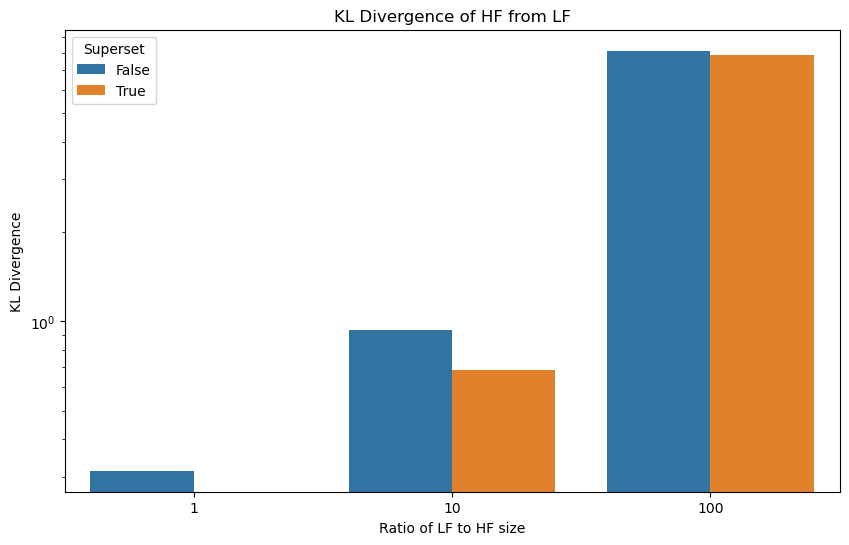

In [6]:
# make sns barplot from kl_divergences

print(kl_divergences)

kl_divergences_df = pd.DataFrame(kl_divergences).T
kl_divergences_df = kl_divergences_df.reset_index().rename(columns={'index': 'Ratio'})
kl_divergences_df = kl_divergences_df.melt(id_vars='Ratio', var_name='Superset', value_name='KL Divergence')

plt.figure(figsize=(10, 6))
sns.barplot(x='Ratio', y='KL Divergence', hue='Superset', data=kl_divergences_df)
plt.title('KL Divergence of HF from LF')
plt.xlabel('Ratio of LF to HF size')
plt.ylabel('KL Divergence')
plt.yscale('log')
plt.show()

In [28]:
# # make sns barplot from kl_divergences_flipped

# print(kl_divergences_flipped)

# kl_divergences_df = pd.DataFrame(kl_divergences_flipped).T
# kl_divergences_df = kl_divergences_df.reset_index().rename(columns={'index': 'Ratio'})
# kl_divergences_df = kl_divergences_df.melt(id_vars='Ratio', var_name='Superset', value_name='KL Divergence')

# plt.figure(figsize=(10, 6))
# sns.barplot(x='Ratio', y='KL Divergence', hue='Superset', data=kl_divergences_df)
# plt.title('KL Divergence of LF from HF')
# plt.xlabel('Ratio of LF to HF size')
# plt.ylabel('KL Divergence')
# plt.yscale('log')
# plt.show()

In [29]:
# # make sns barplot from js_divergences

# print(js_divergences)

# js_divergences_df = pd.DataFrame(js_divergences).T
# js_divergences_df = js_divergences_df.reset_index().rename(columns={'index': 'Ratio'})
# js_divergences_df = js_divergences_df.melt(id_vars='Ratio', var_name='Superset', value_name='JS Divergence')

# plt.figure(figsize=(10, 6))
# sns.barplot(x='Ratio', y='JS Divergence', hue='Superset', data=js_divergences_df)
# plt.title('JS Divergence between HF and LF sets for different ratios and superset configurations')
# plt.xlabel('Ratio of LF to HF size')
# plt.ylabel('JS Divergence')
# plt.yscale('log')
# plt.show()

In [9]:
# from descriptastorus.descriptors.DescriptorGenerator import MakeGenerator
# generator = MakeGenerator(("RDKit2DNormalized",))
# smiles = "c1ccccc1"
# data = generator.process(smiles)
# print(min(data[1:]), max(data[1:]))

# Real Datasets

In [24]:
def calculate_chemical_space_metrics_real(df, lf_col_name, hf_col_name):
    smis_lf = [df['smiles'][i] for i in range(len(df)) if not np.isnan(df[lf_col_name][i])]
    smis_hf = [df['smiles'][i] for i in range(len(df)) if not np.isnan(df[hf_col_name][i])]

    print(f"Size ratio: {len(smis_lf) / len(smis_hf)}")
    print(f"Overlap Fraction (HF): {len(set(smis_lf) & set(smis_hf)) / len(set(smis_hf))}")

    # Convert SMILES to Morgan fingerprints
    fp_set_lf = smiles_to_fingerprints(smis_lf)
    fp_set_hf = smiles_to_fingerprints(smis_hf)

    # Compute KL divergence
    kl_divergence = compute_kl_divergence(fp_set_hf, fp_set_lf)  # this is the correct order - "surprise from using LF as model when HF is the real model"
    js_divergence = compute_js_divergence(fp_set_hf, fp_set_lf)
    print("KL Divergence:", kl_divergence)
    print("JS Divergence:", js_divergence)

    return

### Solubility

In [10]:
sol_df = pd.read_csv('tests/data/SolProp_v1.2_Data/dHsolv_cosmo_expt.csv')
sol_df

,smiles,dHsolv_cosmo,dHsolv_expt
0,O=[N+]([O-])O,-4.951487,NaN
1,FCC(F)C(F)Cl,-6.131453,NaN
2,CCCCCCCCC(N)=O,-14.208665,NaN
3,CC(C)c1ccccc1,-10.158683,NaN
4,FC(F)C(F)C(Cl)(C(F)(F)F)C(F)(F)F,-6.677692,NaN
...,...,...,...
2830,O=C=Nc1ccccc1,-10.032544,NaN
2831,C=C(C)C(C)=O,-7.139154,NaN
2832,CCC(C)(CC)C(F)(F)F,-7.819127,NaN
2833,FC(F)I,-5.868804,NaN


In [25]:
calculate_chemical_space_metrics_real(sol_df, 'dHsolv_cosmo', 'dHsolv_expt')

Size ratio: 57.857142857142854
Overlap Fraction (HF): 1.0
KL Divergence: 10.36263893622718
JS Divergence: 0.0005590671557339773


### Lambda

In [18]:
lambda_df = pd.read_csv('tests/data/lambda_dft_expt.csv')

# choose random sample of 100 data points
# lambda_df = lambda_df.sample(n=100, random_state=0)
# lambda_df.reset_index(drop=True, inplace=True)

lambda_df

,smiles,peakwavs_max,energy_max_osc_nm
0,C1=C2B(Nc3ccccc31)OB1Nc3ccccc3C=C1C(c1ccccc1)=...,413.0,349.295775
1,Cc1ccc(C2=C(c3ccc(C)cc3)C3=Cc4ccccc4NB3OB3Nc4c...,412.0,350.480497
2,Cc1cccc(C2=C(c3cccc(C)c3)C3=Cc4ccccc4NB3OB3Nc4...,413.0,351.573575
3,COc1ccc(C2=C(c3ccc(OC)cc3)C3=Cc4ccccc4NB3OB3Nc...,413.0,351.673284
4,Fc1ccc(C2=C(c3ccc(F)cc3)C3=Cc4ccccc4NB3OB3Nc4c...,413.0,349.985888
...,...,...,...
4958,c1ccc(-[n+]2c3ccc4cccc5c6cccc7c8cccc9ccc2c(c98...,512.0,404.172099
4959,c1cc2ccc3[o+]c4ccc5cccc6c7cccc8c(c1)c2c3c(c87)...,573.0,436.312456
4960,c1cc2ccc3[s+]c4ccc5cccc6c7cccc8c(c1)c2c3c(c87)...,600.0,459.940653
4961,Cc1cc(C)c(C)c(-c2cc(-c3c(C)c(C)cc(C)c3C)c3ccc4...,364.0,319.422978


In [26]:
calculate_chemical_space_metrics_real(lambda_df, 'energy_max_osc_nm', 'peakwavs_max')

Size ratio: 1.0
Overlap Fraction (HF): 1.0
KL Divergence: 0.0
JS Divergence: 0.0


### PubChem

In [20]:
pc_df = pd.read_csv('tests/data/pubchem_AID1445_sd_dr_0.1.csv')
pc_df


,smiles,SD,DR
0,O=C1N=c2ccc(Br)cc2=C1c1sc(=S)n(NS(=O)(=O)c2ccc...,99.86,6.000000
1,CCN1C(=O)C(=Cc2ccc(-c3ccc([N+](=O)[O-])cc3OC)o...,98.34,5.657577
2,Cc1cccc(C)c1OCc1nc2ccccc2c(=O)n1N=Cc1ccc(OCC(=...,97.76,6.000000
3,CC(=O)N1C(=O)C(=C2SC(=S)N(NS(=O)(=O)c3ccc(C)cc...,96.64,5.492144
4,CC(CCC(=O)O)C1CCC2C3C(O)CC4CC(O)CCC4(C)C3CCC12C,94.09,5.585027
...,...,...,...
21294,Cn1cc(C(=O)c2ccc(Cl)cc2Cl)cc1C(=O)NN=C(N)COc1c...,-21.65,NaN
21295,Cc1c(C(=O)NNC(=S)Nc2cccc(Cl)c2)nnn1-c1ccccc1,-22.94,NaN
21296,COc1ccccc1NC(=S)NNC(=O)c1ccc(Cl)cc1Cl,-23.82,NaN
21297,Oc1c(C(Nc2ccccn2)c2cccnc2)cc(Cl)c2cccnc12,-24.05,NaN


In [27]:
calculate_chemical_space_metrics_real(pc_df, 'SD', 'DR')

Size ratio: 32.5175572519084
Overlap Fraction (HF): 1.0
KL Divergence: 5.462291979257374
JS Divergence: 5.71143249182783e-05
